# Завдання 5. Кілька вузлів запиту і мостові вузли

**Пункт 5 ТЗ.** Дослідити поширення релевантності від кількох вузлів запиту одночасно: порівняти адитивне (сума розподілів) та мультиплікативне (добуток, мінімум) поєднання релевантностей від окремих вузлів і встановити, за якого способу найвище ранжуються «мостові» вузли, що лежать на шляхах між вузлами запиту.

**Теорія:**
- **Середнє** π^(a) і π^(b) (адитивне поєднання) за лінійністю дорівнює одному запуску з s = ½(e_a + e_b). Воно ставить високо вузли, близькі хоча б до одного запиту.
- **Добуток і мінімум** нагороджують вузли, до яких маса доходить від обох запитів.
- **Добуток сирих оцінок підсилює хаби подвійно:** далекий вузол отримує від кожного запиту ~d_i, у добутку ~d_i².
- **Степінь у добутку.** За оборотністю π_q(i) = d_i·π_i(q)/d_q, тож добуток сирих оцінок ~ d_i², добуток π/√d ~ d_i¹, добуток π/d ~ d_i⁰. При π/d лишається лише роль хаба «розпорошує масу». Перевіряємо, чи π/√d — компроміс для мостів різного степеня.
- **Нормування π/d:** з оборотності (π_a(i)/d_i)·(π_b(i)/d_i) = π_i(a)·π_i(b)/(d_a·d_b). Для фіксованої пари це ранжування за π_i(a)·π_i(b), тобто за ймовірністю, що блукання з i дійде і до a, і до b (тест `tests/test_multi.py`).

Розподіли рахуємо через `rank` окремо для кожного вузла запиту (з кешем) і поєднуємо функцією `reldiff.multi.combine_scores`. Це те саме, що `rank(..., combine=...)`; збіг перевіряємо нижче.

**Базові методи і нічиї.** У базових методах багато однакових оцінок. Наприклад, сума відстаней d(a, i) + d(i, b) однакова для всіх вузлів на найкоротших шляхах, тож при r ≥ 2 проміжні вузли мають ту саму оцінку, що й правильний міст. Тому для базових методів наводимо три варіанти розбиття нічиїх як межі: random, pessimistic (релевантні в кінці групи нічиїх) і optimistic (на початку).

In [1]:
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

from reldiff.api import rank
from reldiff.multi import combine_scores
from reldiff import graphs as G
from reldiff import metaqa as MQ
from reldiff import metrics as M

FIG = Path("../figures"); RES = Path("../results")
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 250)
COMBS = ["mean", "product", "min"]
TIES = ["random", "pessimistic", "optimistic"]

# Синтетика: 3 спільноти по 200 вузлів, середній степінь усередині ≈ 6, по 3 мости на кожну пару спільнот
N_COMM, SIZE, P_IN, N_BR = 3, 200, 6 / 199, 3
BDEG = [1, 2, 4, 8]
SYN = {b: G.bridged_communities(N_COMM, SIZE, P_IN, n_bridges=N_BR, bridge_degree=b, seed=500 + b) for b in BDEG}
for b, g in SYN.items():
    print(f"bridge_degree = {b}: {g.number_of_nodes()} вузлів, {g.number_of_edges()} ребер, зв'язний: {nx.is_connected(g)}, "
          f"степінь мосту = {2 * b}, середній степінь у спільноті ≈ {np.mean([g.degree(v) for v in g if not g.nodes[v]['is_bridge']]):.2f}")

bridge_degree = 1: 609 вузлів, 1787 ребер, зв'язний: True, степінь мосту = 2, середній степінь у спільноті ≈ 5.93
bridge_degree = 2: 609 вузлів, 1826 ребер, зв'язний: True, степінь мосту = 4, середній степінь у спільноті ≈ 6.03
bridge_degree = 4: 609 вузлів, 1817 ребер, зв'язний: True, степінь мосту = 8, середній степінь у спільноті ≈ 5.94
bridge_degree = 8: 609 вузлів, 1963 ребер, зв'язний: True, степінь мосту = 16, середній степінь у спільноті ≈ 6.30


### Параметри моделей

PPR: α ∈ {0.05, 0.15, 0.5}. Теплове ядро: t = 5.67 і t = 1 (H1 для α = 0.15 і 0.5) і t*(0.05) — емпіричний оптимум за методикою п. 2, бо при α < 0.1 H1 не працює. t*(0.05) рахуємо на синтетичному графі з bridge_degree = 2 (10 запитів).

In [2]:
RESOLVE = 1e-10
def prep(x):
    x = np.asarray(x, dtype=float); m = np.abs(x).max(); x = x / m if m > 0 else x
    x[x < RESOLVE] = 0.0
    return np.round(x, 12)

def topk_idx(x, k):
    pos = np.flatnonzero(x > 0)
    if pos.size <= k: return pos
    thr = np.sort(x[pos])[::-1][k - 1]
    return np.flatnonzero(x >= thr)

def t_star(g, seeds, alpha, ts):
    tau = np.zeros(len(ts))
    for q in seeds:
        xp = prep(rank(g, q, alpha=alpha).drop(index=q))
        for j, t in enumerate(ts):
            xh = prep(rank(g, q, "heat", t=t).drop(index=q))
            U = [i for i in np.union1d(topk_idx(xp, 50), topk_idx(xh, 50)) if xp[i] > 0 and xh[i] > 0]
            tau[j] += kendalltau(xp[U], xh[U]).statistic
    return ts[int(np.argmax(tau))]

g2 = SYN[2]; r0 = np.random.default_rng(1); nodes2 = list(g2.nodes())
T005_SYN = t_star(g2, [nodes2[i] for i in r0.choice(len(nodes2), 10, replace=False)], 0.05, np.logspace(np.log10(2), np.log10(40), 25))
T005_MQ = 7.89   # t*(0.05) для MetaQA з п. 3 (results/03_normuvannya.csv)
MODELS_SYN = [("PPR", "α=0.05", dict(method="ppr", alpha=0.05)), ("PPR", "α=0.15", dict(method="ppr", alpha=0.15)),
              ("PPR", "α=0.5", dict(method="ppr", alpha=0.5)), ("теплове ядро", f"t={T005_SYN:.2f}", dict(method="heat", t=T005_SYN)),
              ("теплове ядро", "t=5.67", dict(method="heat", t=0.85 / 0.15)), ("теплове ядро", "t=1", dict(method="heat", t=1.0))]
print(f"t*(0.05) на синтетиці = {T005_SYN:.2f}; на MetaQA (з п. 3) = {T005_MQ}")

t*(0.05) на синтетиці = 6.97; на MetaQA (з п. 3) = 7.89


## Завдання 5.1. Синтетика з явними мостами

**Правильні мости** для пари запитів зі спільнот (a, b) — вузли з connects = (a, b). Мости, що з'єднують a або b з третьою спільнотою, — **дистрактори**.

Пари запитів добираємо за відстанню r ∈ {1, 2, 3, 4} кожного з двох вузлів до найближчого правильного мосту: 50 пар на конфігурацію (bridge_degree, r), seed фіксований.

**Метрики:**
- MRR і найкращий ранг правильного мосту;
- частка правильних мостів у топ-3 (= кількість мостів) і в топ-10;
- середній ранг дистракторів і їхня частка в топ-10;
- додатковий критерій: частка в топ-10 вузлів, що лежать на найкоротших шляхах між запитами.

Вузли запиту з ранжування виключено.

In [3]:
def sample_pairs(g, r, n_pairs, seed):
    rng = np.random.default_rng(seed)
    comm = G.communities(g)
    out = []
    pairs_ab = [(a, b) for a in range(N_COMM) for b in range(a + 1, N_COMM)]
    cand = {}
    for a, b in pairs_ab:
        correct = [v for v, c in g.nodes(data="connects") if c == (a, b)]
        dist = nx.multi_source_dijkstra_path_length(g, correct)
        U = sorted(v for v in comm[a] if dist.get(v) == r); V = sorted(v for v in comm[b] if dist.get(v) == r)
        if U and V: cand[(a, b)] = (U, V, correct)
    if not cand: return []
    keys = sorted(cand)
    for _ in range(n_pairs):
        a, b = keys[int(rng.integers(len(keys)))]
        U, V, correct = cand[(a, b)]
        out.append(dict(a=a, b=b, u=U[int(rng.integers(len(U)))], v=V[int(rng.integers(len(V)))], correct=correct))
    return out

def eval_bridges(scores, seeds, correct, distract, spn, ties, seed=0):
    order = M.ranking(scores, relevant=set(correct), seeds=seeds, ties=ties, seed=seed)
    pos = {v: i + 1 for i, v in enumerate(order)}
    rc = [pos.get(c, np.inf) for c in correct]; rd = [pos.get(c, np.inf) for c in distract]
    top10 = set(order[:10])
    return dict(MRR=1 / min(rc), найкращий_ранг=min(rc), мости_в_топ3=np.mean([x <= 3 for x in rc]),
                мости_в_топ10=np.mean([x <= 10 for x in rc]),
                ранг_дистракторів=np.mean(np.minimum(rd, len(scores))), дистрактори_в_топ10=len(top10 & set(distract)) / 10,
                шляхові_в_топ10=len(top10 & spn) / 10)

BASELINES = [("спільні сусіди запитів (k-hop ∩, k=1)", dict(method="k_hop", hops=1, agg="max")),
             ("схожість Σ|N(v)∩N(q)|", dict(method="common_neighbors")),
             ("найкор. шлях, сума (agg=mean)", dict(method="shortest_path", agg="mean")),
             ("найкор. шлях, max", dict(method="shortest_path", agg="max")),
             ("k-hop ∩, k=2", dict(method="k_hop", hops=2, agg="max")),
             ("k-hop ∩, k=3", dict(method="k_hop", hops=3, agg="max"))]

NORMS_SYN = [(None, "сирі"), ("sqrt_degree", "π/√d"), ("degree", "π/d")]
rows, skipped = [], []
checked = False
KEEP = {}   # оцінки для розбору r = 1 (доповнення 2)
for b, g in SYN.items():
    for r in (1, 2, 3, 4):
        pairs = sample_pairs(g, r, 50, seed=1000 * b + r)
        if len(pairs) == 0:
            skipped.append((b, r)); continue
        cache = {}
        def single(q, key, kw, norm):
            k = (q, key, norm)
            if k not in cache:
                cache[k] = rank(g, q, normalize=norm, **kw)
            return cache[k]
        for pr in pairs:
            u, v, a, bb, correct = pr["u"], pr["v"], pr["a"], pr["b"], pr["correct"]
            distract = [w for w, c in g.nodes(data="connects") if c is not None and c != (a, bb) and (a in c or bb in c)]
            du = nx.single_source_shortest_path_length(g, u); dv = nx.single_source_shortest_path_length(g, v)
            spn = {w for w in g if w not in (u, v) and du[w] + dv[w] == du[v]}
            for model, pname, kw in MODELS_SYN:
                for norm, nlab in NORMS_SYN:
                    parts = [single(u, pname, kw, norm), single(v, pname, kw, norm)]
                    for comb in COMBS:
                        sc = combine_scores(parts, comb)
                        if r == 1 and comb == "min" and nlab == "π/d" and pname in ("α=0.15", "t=5.67"):
                            KEEP.setdefault((b, pname), []).append((u, v, correct, distract, spn, sc))
                        if not checked:
                            ref = rank(g, [u, v], normalize=norm, combine=comb, **kw)
                            assert np.allclose(sc.to_numpy(), ref.to_numpy(), atol=1e-14); checked = True
                        rows.append(dict(bridge_degree=b, r=r, метод=f"{model}, {pname}", модель=model, параметр=pname,
                                         нормування=nlab, поєднання=comb, нічиї="random",
                                         **eval_bridges(sc, [u, v], correct, distract, spn, "random")))
            for bname, kw in BASELINES:
                sc = rank(g, [u, v], **kw)
                for ties in TIES:
                    rows.append(dict(bridge_degree=b, r=r, метод=bname, модель="базовий", параметр="", нормування="",
                                     поєднання="", нічиї=ties, **eval_bridges(sc, [u, v], correct, distract, spn, ties)))
syn = pd.DataFrame(rows)
key = ["bridge_degree", "r", "метод", "модель", "параметр", "нормування", "поєднання", "нічиї"]
syn_m = syn.groupby(key, sort=False).mean(numeric_only=True).reset_index()
syn_m.to_csv(RES / "05_mosty_syntetyka.csv", index=False)
print("Перевірка: combine_scores = rank(combine=...) — так" if checked else "")
print("Пропущені конфігурації (немає пар на такій відстані):", skipped)

Перевірка: combine_scores = rank(combine=...) — так
Пропущені конфігурації (немає пар на такій відстані): []


In [4]:
# Зведення: найкращий дифузійний варіант для кожного (поєднання, нормування) і базові методи
diff = syn_m[syn_m["модель"] != "базовий"]
summ = diff.groupby(["поєднання", "нормування", "r"])["MRR"].mean().unstack("r")
print("Середній MRR правильних мостів (усереднено за bridge_degree і 6 варіантами моделей):")
display(summ)
base = syn_m[syn_m["модель"] == "базовий"].groupby(["метод", "нічиї", "r"])["MRR"].mean().unstack("r")
print("Базові методи (усереднено за bridge_degree):")
display(base)
best = diff.groupby(["метод", "нормування", "поєднання"])["MRR"].mean().sort_values(ascending=False).head(10)
print("Топ-10 дифузійних варіантів за середнім MRR:"); display(best)

Середній MRR правильних мостів (усереднено за bridge_degree і 6 варіантами моделей):


r                        1     2     3     4
поєднання нормування                        
mean      π/d        0.518 0.078 0.013 0.004
          π/√d       0.635 0.054 0.012 0.006
          сирі       0.589 0.065 0.019 0.010
min       π/d        0.559 0.871 0.981 0.999
          π/√d       0.593 0.845 0.966 0.999
          сирі       0.587 0.789 0.908 0.989
product   π/d        0.881 0.786 0.769 0.733
          π/√d       0.861 0.746 0.756 0.681
          сирі       0.727 0.560 0.526 0.484

Базові методи (усереднено за bridge_degree):


r                                                     1     2     3     4
метод                                 нічиї                              
k-hop ∩, k=2                          optimistic  0.500 0.440 0.000 0.000
                                      pessimistic 0.383 0.438 0.000 0.000
                                      random      0.448 0.440 0.000 0.000
k-hop ∩, k=3                          optimistic  0.645 0.882 0.670 0.000
                                      pessimistic 0.395 0.519 0.635 0.000
                                      random      0.454 0.662 0.659 0.000
найкор. шлях, max                     optimistic  0.657 0.927 0.987 0.998
                                      pessimistic 0.397 0.525 0.697 0.821
                                      random      0.468 0.723 0.869 0.907
найкор. шлях, сума (agg=mean)         optimistic  1.000 0.996 0.983 0.939
                                      pessimistic 0.509 0.226 0.118 0.057
                                      random      0.696 0.586 0.471 0.321
спільні сусіди запитів (k-hop ∩, k=1) optimistic  0.340 0.000 0.000 0.000
                                      pessimistic 0.340 0.000 0.000 0.000
                                      random      0.340 0.000 0.000 0.000
схожість Σ|N(v)∩N(q)|                 optimistic  0.103 0.548 0.016 0.024
                                      pessimistic 0.024 0.124 0.002 0.002
                                      random      0.054 0.268 0.010 0.010

Топ-10 дифузійних варіантів за середнім MRR:


метод                 нормування  поєднання
теплове ядро, t=6.97  π/d         product     0.945
теплове ядро, t=5.67  π/d         product     0.924
PPR, α=0.05           π/√d        min         0.901
                      π/d         min         0.896
теплове ядро, t=1     π/√d        product     0.891
теплове ядро, t=6.97  π/d         min         0.878
                      π/√d        min         0.876
теплове ядро, t=5.67  π/√d        product     0.868
                      π/d         min         0.855
PPR, α=0.15           π/d         min         0.855
Name: MRR, dtype: float64

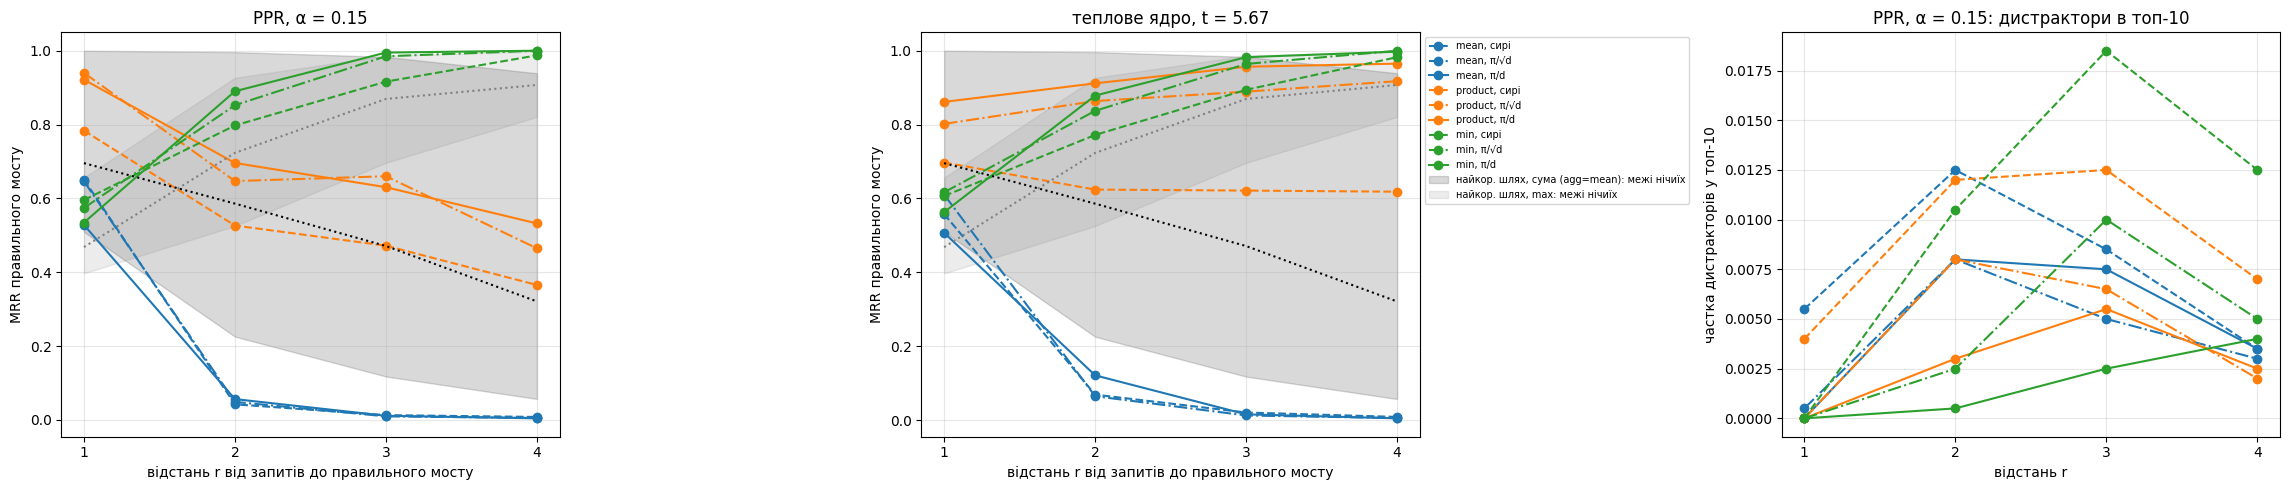

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(23, 5))
rs = [1, 2, 3, 4]
for ax, model_sel, title in ((axs[0], "PPR, α=0.15", "PPR, α = 0.15"), (axs[1], "теплове ядро, t=5.67", "теплове ядро, t = 5.67")):
    for i, comb in enumerate(COMBS):
        for nlab, ls in (("сирі", "--"), ("π/√d", "-."), ("π/d", "-")):
            sub = diff[(diff["метод"] == model_sel) & (diff["поєднання"] == comb) & (diff["нормування"] == nlab)]
            y = sub.groupby("r")["MRR"].mean().reindex(rs)
            ax.plot(rs, y, ls, marker="o", color=f"C{i}", label=f"{comb}, {nlab}")
    for bname, c in (("найкор. шлях, сума (agg=mean)", "k"), ("найкор. шлях, max", "gray")):
        sub = syn_m[syn_m["метод"] == bname]
        lo = sub[sub["нічиї"] == "pessimistic"].groupby("r")["MRR"].mean().reindex(rs)
        hi = sub[sub["нічиї"] == "optimistic"].groupby("r")["MRR"].mean().reindex(rs)
        ax.fill_between(rs, lo, hi, color=c, alpha=0.15, label=f"{bname}: межі нічиїх")
        ax.plot(rs, sub[sub["нічиї"] == "random"].groupby("r")["MRR"].mean().reindex(rs), ":", color=c)
    ax.set_title(title); ax.set_xlabel("відстань r від запитів до правильного мосту"); ax.set_ylabel("MRR правильного мосту")
    ax.set_xticks(rs); ax.grid(alpha=0.3)
axs[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
for i, comb in enumerate(COMBS):
    for nlab, ls in (("сирі", "--"), ("π/√d", "-."), ("π/d", "-")):
        sub = diff[(diff["метод"] == "PPR, α=0.15") & (diff["поєднання"] == comb) & (diff["нормування"] == nlab)]
        y = sub.groupby("r")["дистрактори_в_топ10"].mean().reindex(rs)
        axs[2].plot(rs, y, ls, marker="o", color=f"C{i}", label=f"{comb}, {nlab}")
axs[2].set_title("PPR, α = 0.15: дистрактори в топ-10"); axs[2].set_xlabel("відстань r"); axs[2].set_ylabel("частка дистракторів у топ-10")
axs[2].set_xticks(rs); axs[2].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "05_mosty_vidstan.png", dpi=200); plt.show()

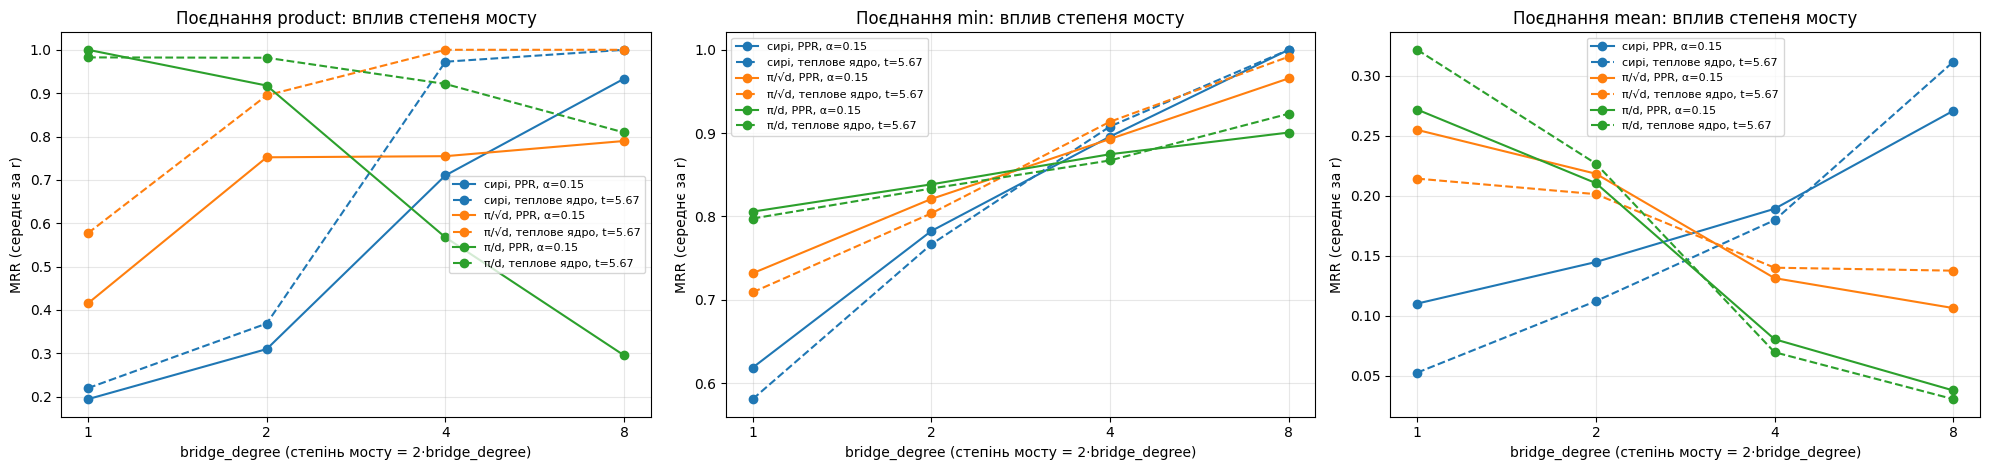

bridge_degree                                 1     2     4     8
метод                поєднання нормування                        
PPR, α=0.15          mean      π/d        0.272 0.210 0.081 0.038
                               π/√d       0.255 0.218 0.131 0.107
                               сирі       0.110 0.145 0.189 0.271
                     min       π/d        0.806 0.839 0.875 0.901
                               π/√d       0.732 0.821 0.893 0.966
                               сирі       0.619 0.783 0.896 1.000
                     product   π/d        1.000 0.917 0.568 0.295
                               π/√d       0.416 0.752 0.755 0.790
                               сирі       0.194 0.310 0.710 0.933
теплове ядро, t=5.67 mean      π/d        0.321 0.227 0.070 0.031
                               π/√d       0.214 0.201 0.140 0.138
                               сирі       0.053 0.112 0.180 0.311
                     min       π/d        0.798 0.834 0.867 0.923
                               π/√d       0.709 0.804 0.914 0.992
                               сирі       0.581 0.767 0.908 1.000
                     product   π/d        0.982 0.982 0.921 0.809
                               π/√d       0.577 0.895 1.000 1.000
                               сирі       0.220 0.369 0.972 1.000

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, comb in zip(axs, ("product", "min", "mean")):
    for i, nlab in enumerate(("сирі", "π/√d", "π/d")):
        for model_sel, ls in (("PPR, α=0.15", "-"), ("теплове ядро, t=5.67", "--")):
            sub = diff[(diff["метод"] == model_sel) & (diff["поєднання"] == comb) & (diff["нормування"] == nlab)]
            y = sub.groupby("bridge_degree")["MRR"].mean().reindex(BDEG)
            ax.plot(BDEG, y, ls, marker="o", color=f"C{i}", label=f"{nlab}, {model_sel}")
    ax.set_xscale("log", base=2); ax.set_xticks(BDEG); ax.set_xticklabels(BDEG)
    ax.set_xlabel("bridge_degree (степінь мосту = 2·bridge_degree)"); ax.set_ylabel("MRR (середнє за r)")
    ax.set_title(f"Поєднання {comb}: вплив степеня мосту"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_mosty_stepin.png", dpi=200); plt.show()
display(diff[diff["метод"].isin(["PPR, α=0.15", "теплове ядро, t=5.67"])].groupby(["метод", "поєднання", "нормування", "bridge_degree"])["MRR"].mean().unstack("bridge_degree"))

### Чому мінімум з π/d гірший при r = 1, ніж при r = 4

Для r = 1 (запити суміжні з правильним мостом) дивимося, які вузли стоять вище за найкращий правильний міст. Беремо мінімум з π/d для PPR (α = 0.15) і теплового ядра (t = 5.67). Кожен такий вузол відносимо до першого підхожого класу:
1. дистрактор — міст до третьої спільноти;
2. вузол на найкоротшому шляху між запитами;
3. сусід запиту — суміжний з u або v;
4. інший.

In [7]:
rows, examples = [], []
for (b, pname), items in KEEP.items():
    g = SYN[b]
    for u, v, correct, distract, spn, sc in items:
        order = M.ranking(sc, seeds=[u, v], ties="random", seed=0)
        pos = {w: i for i, w in enumerate(order)}
        best = min(pos[c] for c in correct)
        above = order[:best]
        nu, nv = set(g.neighbors(u)), set(g.neighbors(v))
        for w in above:
            if w in distract: cls = "дистрактор (інший міст)"
            elif w in spn: cls = "на найкоротшому шляху"
            elif w in nu or w in nv: cls = "сусід запиту"
            else: cls = "інший"
            rows.append(dict(bridge_degree=b, модель=pname, клас=cls, степінь=g.degree(w),
                             сусід_обох=(w in nu and w in nv)))
            if len(examples) < 12 and pname == "α=0.15":
                examples.append(dict(bridge_degree=b, u=u, v=v, вузол=w, клас=cls, степінь=g.degree(w),
                                     степінь_правильного_мосту=g.degree(correct[0]),
                                     оцінка_вузла=sc[w], оцінка_мосту=max(sc[c] for c in correct)))
        rows.append(dict(bridge_degree=b, модель=pname, клас="(пара)", степінь=np.nan, сусід_обох=False))
above_t = pd.DataFrame(rows)
n_pairs = above_t[above_t["клас"] == "(пара)"].groupby(["модель", "bridge_degree"]).size()
cnt = above_t[above_t["клас"] != "(пара)"].groupby(["модель", "bridge_degree", "клас"]).size().unstack(fill_value=0)
cnt = cnt.div(n_pairs, axis=0)
cnt.to_csv(RES / "05_r1_vyshche_za_mist.csv")
print("Середня кількість вузлів вище за правильний міст на одну пару, r = 1, мінімум з π/d:")
display(cnt)
deg = above_t[above_t["клас"] != "(пара)"].groupby(["модель", "клас"])["степінь"].median()
print("Медіанний степінь таких вузлів:"); display(deg)
print("Приклади (PPR, α = 0.15):"); display(pd.DataFrame(examples))

Середня кількість вузлів вище за правильний міст на одну пару, r = 1, мінімум з π/d:


клас                  на найкоротшому шляху  інший
модель bridge_degree                              
t=5.67 1                              1.660  4.060
       2                              1.220  3.400
       4                              0.640  3.320
       8                              0.380  1.720
α=0.15 1                              1.660  3.060
       2                              1.240  2.940
       4                              0.960  3.640
       8                              0.720  3.240

Медіанний степінь таких вузлів:


модель  клас                 
t=5.67  на найкоротшому шляху   7.000
        інший                   6.000
α=0.15  на найкоротшому шляху   7.000
        інший                   6.000
Name: степінь, dtype: float64

Приклади (PPR, α = 0.15):


,bridge_degree,u,v,вузол,клас,степінь,степінь_правильного_мосту,оцінка_вузла,оцінка_мосту
0,1,111,202,351,на найкоротшому шляху,5,2,0.001,0.000
1,1,111,202,203,інший,3,2,0.000,0.000
2,1,111,202,83,на найкоротшому шляху,11,2,0.000,0.000
3,1,365,440,310,на найкоротшому шляху,6,2,0.000,0.000
4,1,365,440,346,інший,7,2,0.000,0.000
5,1,365,440,350,інший,4,2,0.000,0.000
6,1,365,440,429,інший,7,2,0.000,0.000
7,1,365,440,573,інший,4,2,0.000,0.000
8,1,365,440,230,на найкоротшому шляху,3,2,0.000,0.000
9,1,365,440,549,інший,7,2,0.000,0.000


**Пояснення немонотонності.** r — відстань до **найближчого** правильного мосту, тож два вузли запиту можуть бути приєднані до різних мостів. Тоді кожен правильний міст близький лише до одного запиту, і мінімум нагороджує «врівноважені» вузли посередині шляху між ними. Нижче для кожного r — частка пар, у яких є спільний міст на відстані r від обох запитів, і MRR (мінімум з π/d, PPR α = 0.15) окремо для пар зі спільним мостом і без нього.

In [8]:
rows = []
for b, g in SYN.items():
    for r in (1, 2, 3, 4):
        for pr in sample_pairs(g, r, 50, seed=1000 * b + r):
            u, v, correct = pr["u"], pr["v"], pr["correct"]
            du = nx.single_source_shortest_path_length(g, u); dv = nx.single_source_shortest_path_length(g, v)
            same = any(du[c] == r and dv[c] == r for c in correct)
            sc = rank(g, [u, v], alpha=0.15, normalize="degree", combine="min")
            rows.append(dict(bridge_degree=b, r=r, спільний_міст=same, відстань_між_запитами=du[v],
                             MRR=M.reciprocal_rank(sc, set(correct), seeds=[u, v])))
shared = pd.DataFrame(rows)
shared.to_csv(RES / "05_spilnyi_mist.csv", index=False)
display(shared.groupby("r").agg(частка_пар_зі_спільним_мостом=("спільний_міст", "mean"),
                                сер_відстань_між_запитами=("відстань_між_запитами", "mean"), MRR=("MRR", "mean")))
display(shared.groupby(["r", "спільний_міст"])["MRR"].agg(["mean", "count"]))

,частка_пар_зі_спільним_мостом,сер_відстань_між_запитами,MRR
r,,,
1,0.340,3.370,0.535
2,0.440,4.695,0.890
3,0.670,6.330,0.995
4,0.970,7.955,1.000


mean  count
r спільний_міст             
1 False         0.295    132
  True          1.000     68
2 False         0.804    112
  True          1.000     88
3 False         0.985     66
  True          1.000    134
4 False         1.000      6
  True          1.000    194

### Верхня межа дифузії проти базових методів

**Увага:** тут для кожного r береться найкращий з ~18 дифузійних варіантів. Це вибір найкращого з багатьох, тож таблиця **завищує** дифузію і показує лише її верхню межу. Чесне порівняння одного фіксованого варіанта з одним фіксованим базовим методом — у розділі 5.3.

Для кожної відстані r порівнюємо найкращий дифузійний варіант (за середнім MRR по bridge_degree) з **оптимістичною** межею найкращого базового методу: нічиї розбито на користь правильних мостів. Якщо дифузія виграє лише в pessimistic- або random-варіантів, її перевага полягає в тому, що вона розрізняє вузли, які простий метод вважає рівними, а не в тому, що вона краще знаходить мости.

In [9]:
rows = []
for r in (1, 2, 3, 4):
    d = diff[diff["r"] == r].groupby(["метод", "нормування", "поєднання"])["MRR"].mean()
    bb = syn_m[(syn_m["модель"] == "базовий") & (syn_m["r"] == r)].groupby(["метод", "нічиї"])["MRR"].mean().unstack("нічиї")
    best_b = bb["optimistic"].idxmax()
    rows.append(dict(r=r, дифузія_найкраща=" / ".join(d.idxmax()), MRR_дифузії=d.max(),
                     базовий_найкращий=best_b, MRR_opt=bb.loc[best_b, "optimistic"], MRR_random=bb.loc[best_b, "random"],
                     MRR_pess=bb.loc[best_b, "pessimistic"]))
vs = pd.DataFrame(rows); vs.to_csv(RES / "05_dyfuziya_vs_bazovi.csv", index=False)
display(vs)

,r,дифузія_найкраща,MRR_дифузії,базовий_найкращий,MRR_opt,MRR_random,MRR_pess
0,1,"PPR, α=0.15 / π/√d / product",0.940,"найкор. шлях, сума (agg=mean)",1.000,0.696,0.509
1,2,"теплове ядро, t=6.97 / π/d / product",0.958,"найкор. шлях, сума (agg=mean)",0.996,0.586,0.226
2,3,"PPR, α=0.05 / π/d / min",1.000,"найкор. шлях, max",0.987,0.869,0.697
3,4,"PPR, α=0.05 / π/d / min",1.000,"найкор. шлях, max",0.998,0.907,0.821


## Завдання 5.2. MetaQA: пари акторів і пари «актор + режисер»

Стратифікована вибірка: до 300 пар кожного типу, seed = 0. Правильні відповіді — спільні фільми в підграфі. Метрики: MRR, hits@1, recall@5, recall@10 і мінімальна кількість верхніх вузлів, що охоплює всі відповіді.

**Еталон-оракул — спільні сусіди запитів**, тобто вузли, суміжні з обома запитами (k-hop ∩ з k = 1). MetaQA майже дводольний, тож спільні фільми двох людей — це їхні спільні сусіди. Питання: чи досягає дифузія рівня цього ідеального простого методу.

Метод «спільні сусіди» з етапу 3 рахує іншу величину: оцінка вузла v дорівнює Σ_q |N(v) ∩ N(q)|. Це схожість кандидата на запити (як у задачі передбачення зв'язків), і вона ставить угорі інших людей, а не спільні фільми. Наводимо його окремо під назвою «схожість Σ|N(v)∩N(q)|».

Нормування для дифузії: сирі оцінки, π/d, IDF-граф (β = 0.5 і 1).

In [10]:
g, q_mq, pairs_all = MQ.load_processed("../data/metaqa", 500, 0)
edges = pd.read_csv("../data/metaqa/processed/movies500_seed0/subgraph_edges.csv", dtype=str, keep_default_na=False)
deg_un = dict(g.degree())
def idf_graph(beta):
    h = nx.MultiGraph(); h.add_nodes_from(g.nodes(data=True))
    for s_, r_, o_ in edges.itertuples(index=False, name=None):
        h.add_edge(s_, o_, type=r_, weight=deg_un[o_] ** (-beta))
    return h
GRAPHS = {"сирі": (g, None), "π/√d": (g, "sqrt_degree"), "π/d": (g, "degree"),
          "IDF β=0.5": (idf_graph(0.5), None), "IDF β=1": (idf_graph(1.0), None)}

rng = np.random.default_rng(0)
sample = pd.concat([grp.iloc[np.sort(rng.choice(len(grp), min(300, len(grp)), replace=False))]
                    for _, grp in pairs_all.groupby("kind", sort=True)]).reset_index(drop=True)
print(sample.groupby("kind").agg(пар=("kind", "size"), повних=("complete_wrt_full_kb", "sum"),
                                  сер_відповідей=("n_answers", "mean")))

# Скільки «спільних сусідів» не є відповідями (напр. режисер лише сценарист фільму)
extra = []
for p in sample.itertuples():
    cn = set(g.neighbors(p.seed_1)) & set(g.neighbors(p.seed_2))
    extra.append(len(cn - set(p.answers)))
sample["зайвих_спільних_сусідів"] = extra
print("Пар, де серед спільних сусідів є не-відповіді:", sample.groupby("kind")["зайвих_спільних_сусідів"].apply(lambda x: int((x > 0).sum())).to_dict())

MODELS_MQ = [("PPR", "α=0.05", dict(method="ppr", alpha=0.05)), ("PPR", "α=0.15", dict(method="ppr", alpha=0.15)),
             ("PPR", "α=0.5", dict(method="ppr", alpha=0.5)), ("теплове ядро", f"t={T005_MQ}", dict(method="heat", t=T005_MQ)),
             ("теплове ядро", "t=5.67", dict(method="heat", t=0.85 / 0.15)), ("теплове ядро", "t=1", dict(method="heat", t=1.0))]

def eval_answers(scores, seeds, answers, ties, seed=0):
    kw = dict(seeds=seeds, ties=ties, seed=seed)
    return dict(MRR=M.reciprocal_rank(scores, answers, **kw),
                hits1=M.precision_at_k(scores, answers, 1, **kw),
                recall5=M.precision_at_k(scores, answers, 5, **kw) * 5 / len(answers),
                recall10=M.precision_at_k(scores, answers, 10, **kw) * 10 / len(answers),
                охоплення=M.coverage_size(scores, answers, **kw))

cache, rows = {}, []
for p in sample.itertuples():
    seeds = [p.seed_1, p.seed_2]; ans = set(p.answers)
    for model, pname, kw in MODELS_MQ:
        for nlab, (gg, norm) in GRAPHS.items():
            parts = []
            for q in seeds:
                k = (q, pname, nlab)
                if k not in cache:
                    cache[k] = rank(gg, q, normalize=norm, **kw)
                parts.append(cache[k])
            for comb in COMBS:
                rows.append(dict(kind=p.kind, повна=p.complete_wrt_full_kb, метод=f"{model}, {pname}", модель=model,
                                 нормування=nlab, поєднання=comb, нічиї="random",
                                 **eval_answers(combine_scores(parts, comb), seeds, ans, "random")))
    for bname, kw in (("спільні сусіди запитів (оракул)", dict(method="k_hop", hops=1, agg="max")),
                      ("схожість Σ|N(v)∩N(q)|", dict(method="common_neighbors")),
                      ("найкор. шлях, сума (agg=mean)", dict(method="shortest_path", agg="mean"))):
        sc = rank(g, seeds, **kw)
        for ties in TIES:
            rows.append(dict(kind=p.kind, повна=p.complete_wrt_full_kb, метод=bname, модель="базовий", нормування="",
                             поєднання="", нічиї=ties, **eval_answers(sc, seeds, ans, ties)))
mq = pd.DataFrame(rows)
mq_m = mq.groupby(["kind", "метод", "модель", "нормування", "поєднання", "нічиї"], sort=False).mean(numeric_only=True).reset_index()
mq_m.to_csv(RES / "05_metaqa_pary.csv", index=False)
print(f"Розподілів у кеші: {len(cache)}")

                пар  повних  сер_відповідей
kind                                       
actor_actor     300     290           1.017
actor_director  300     286           1.027
Пар, де серед спільних сусідів є не-відповіді: {'actor_actor': 0, 'actor_director': 1}


Розподілів у кеші: 21000


In [11]:
mq_m["охоплення"] = mq_m["охоплення"].replace(np.inf, np.nan)
show = mq_m[(mq_m["модель"] == "базовий") | (mq_m["метод"].isin(["PPR, α=0.15", "теплове ядро, t=5.67"]))]
display(show.pivot_table(index=["метод", "нормування", "поєднання", "нічиї"], columns="kind", values=["MRR", "hits1", "recall5"], sort=False))

# Частка пар, де MRR дифузії ≥ MRR оракула (оптимістична межа: найсуворіше для дифузії)
mq["пара"] = mq.groupby(["метод", "нормування", "поєднання", "нічиї"]).cumcount()
oracle = {t: mq[(mq["метод"] == "спільні сусіди запитів (оракул)") & (mq["нічиї"] == t)].set_index("пара")["MRR"] for t in TIES}
d = mq[mq["модель"] != "базовий"].copy()
for t in TIES:
    d[f"≥_оракула_{t}"] = d["MRR"].to_numpy() >= oracle[t].reindex(d["пара"]).to_numpy() - 1e-12
reach = d.groupby(["kind", "метод", "нормування", "поєднання"])[[f"≥_оракула_{t}" for t in TIES] + ["MRR"]].mean().reset_index()
reach.to_csv(RES / "05_metaqa_dosyagaye_orakula.csv", index=False)
print("Найкращі дифузійні варіанти за часткою пар, де MRR ≥ MRR оракула з оптимістичними нічиями:")
display(reach.sort_values("≥_оракула_optimistic", ascending=False).groupby("kind").head(6))

MRR                      hits1                    recall5               
kind                                                             actor_actor actor_director actor_actor actor_director actor_actor actor_director
метод                           нормування поєднання нічиї                                                                                       
PPR, α=0.15                     сирі       mean      random            0.962          0.961       0.937          0.933       0.993          0.990
                                           product   random            0.988          0.994       0.980          0.990       1.000          1.000
                                           min       random            0.872          0.925       0.787          0.870       0.996          1.000
                                π/√d       mean      random            0.962          0.944       0.937          0.907       0.990          0.983
                                           product   random            1.000          1.000       1.000          1.000       1.000          1.000
                                           min       random            0.955          0.981       0.917          0.967       1.000          1.000
                                π/d        mean      random            0.929          0.903       0.900          0.867       0.957          0.949
                                           product   random            0.993          0.995       0.990          0.990       0.995          0.996
                                           min       random            0.952          0.947       0.923          0.917       0.987          0.989
                                IDF β=0.5  mean      random            0.959          0.950       0.933          0.913       0.990          0.990
                                           product   random            1.000          0.998       1.000          0.997       1.000          1.000
                                           min       random            0.983          0.991       0.970          0.983       0.997          1.000
                                IDF β=1    mean      random            0.949          0.947       0.920          0.910       0.987          0.990
                                           product   random            0.994          0.995       0.990          0.990       1.000          1.000
                                           min       random            0.982          0.992       0.967          0.987       1.000          1.000
теплове ядро, t=5.67            сирі       mean      random            0.931          0.929       0.897          0.887       0.972          0.987
                                           product   random            0.939          0.959       0.900          0.930       0.996          0.993
                                           min       random            0.815          0.855       0.707          0.773       0.963          0.973
                                π/√d       mean      random            0.939          0.936       0.907          0.900       0.980          0.977
                                           product   random            0.995          0.992       0.993          0.987       0.997          0.997
                                           min       random            0.924          0.951       0.870          0.920       0.989          1.000
                                π/d        mean      random            0.235          0.243       0.033          0.037       0.489          0.503
                                           product   random            0.267          0.263       0.043          0.040       0.574          0.557
                                           min       random            0.258          0.266       0.050          0.047       0.534          0.548
                                IDF β=0.5  mean      random            0.928          0.937       0.890          0.897       0.977 

Найкращі дифузійні варіанти за часткою пар, де MRR ≥ MRR оракула з оптимістичними нічиями:


,kind,метод,нормування,поєднання,≥_оракула_random,≥_оракула_pessimistic,≥_оракула_optimistic,MRR
17,actor_actor,"PPR, α=0.15",IDF β=0.5,product,1.000,1.000,1.000,1.000
32,actor_actor,"PPR, α=0.5",IDF β=0.5,product,1.000,1.000,1.000,1.000
35,actor_actor,"PPR, α=0.5",IDF β=1,product,1.000,1.000,1.000,1.000
26,actor_actor,"PPR, α=0.15",π/√d,product,1.000,1.000,1.000,1.000
38,actor_actor,"PPR, α=0.5",π/d,product,1.000,1.000,1.000,1.000
41,actor_actor,"PPR, α=0.5",π/√d,product,1.000,1.000,1.000,1.000
134,actor_director,"PPR, α=0.5",сирі,product,1.000,1.000,1.000,1.000
140,actor_director,"теплове ядро, t=1",IDF β=1,product,1.000,1.000,1.000,1.000
143,actor_director,"теплове ядро, t=1",π/d,product,1.000,1.000,1.000,1.000
146,actor_director,"теплове ядро, t=1",π/√d,product,1.000,1.000,1.000,1.000


### Чому теплове ядро з π/d слабке на MetaQA

**Гіпотеза:** вузли степеня 1, приєднані до спільного фільму (теги, сценаристи, інші люди з одним фільмом), після ділення на d отримують оцінку, порівнянну з оцінкою самого фільму. Теплове ядро менш локальне за PPR, тож перекорекція з п. 3 у нього сильніша.

Для пар actor_actor дивимося, що стоїть вище за найкращий правильний фільм. Беремо поєднання mean і product: теплове ядро (t = 5.67) і PPR (α = 0.15), обидва з π/d.

In [12]:
PRIOR = ["movie", "actor", "director", "writer", "genre", "year", "language", "tag", "imdb_rating", "imdb_votes"]
UA = {"movie": "фільм", "actor": "людина", "director": "людина", "writer": "людина", "genre": "жанр", "year": "рік",
      "language": "мова", "tag": "тег", "imdb_rating": "imdb", "imdb_votes": "imdb"}
kind_of = {v: UA[min(k, key=PRIOR.index)] for v, k in g.nodes(data="kinds")}
rows = []
aa = sample[sample["kind"] == "actor_actor"]
for model, pname in (("теплове ядро", "t=5.67"), ("PPR", "α=0.15")):
    for comb in ("mean", "product"):
        for p in aa.itertuples():
            seeds = [p.seed_1, p.seed_2]; ans = set(p.answers)
            sc = combine_scores([cache[(q, pname, "π/d")] for q in seeds], comb)
            order = M.ranking(sc, seeds=seeds, ties="random", seed=0)
            pos = {w: i for i, w in enumerate(order)}
            best = min(pos[a] for a in ans)
            ans_nb = set().union(*[set(g.neighbors(a)) for a in ans])
            for w in order[:best]:
                rows.append(dict(модель=model, поєднання=comb, тип=kind_of[w], степінь_1=deg_un[w] == 1,
                                 сусід_правильного_фільму=w in ans_nb,
                                 відношення_оцінок=sc[w] / max(sc[a] for a in ans)))
            rows.append(dict(модель=model, поєднання=comb, тип="(пара)"))
ab = pd.DataFrame(rows)
npair = ab[ab["тип"] == "(пара)"].groupby(["модель", "поєднання"]).size()
real = ab[ab["тип"] != "(пара)"]
summ = real.groupby(["модель", "поєднання"]).agg(вузлів_вище=("тип", "size"), частка_степеня_1=("степінь_1", "mean"),
                                                   частка_сусідів_правильного_фільму=("сусід_правильного_фільму", "mean"),
                                                   медіана_відношення_оцінок=("відношення_оцінок", "median"))
summ["вузлів_вище_на_пару"] = summ["вузлів_вище"] / npair
display(summ)
display((real.groupby(["модель", "поєднання", "тип"]).size().unstack(fill_value=0).div(npair, axis=0)))
summ.to_csv(RES / "05_metaqa_heat_pi_d_rozbir.csv")

вузлів_вище частка_степеня_1 частка_сусідів_правильного_фільму  медіана_відношення_оцінок  вузлів_вище_на_пару
модель       поєднання                                                                                                                
PPR          mean               232            0.539                             0.017                      1.280                0.773
             product              9            0.222                             0.111                      1.717                0.030
теплове ядро mean              2159            0.840                             0.676                      1.237                7.197
             product           1517            0.902                             0.955                      1.451                5.057

тип                     жанр  людина  мова   рік   тег  фільм
модель       поєднання                                       
PPR          mean      0.000   0.373 0.000 0.000 0.127  0.273
             product   0.000   0.017 0.000 0.000 0.003  0.010
теплове ядро mean      0.020   4.313 0.023 0.103 2.340  0.397
             product   0.010   3.073 0.017 0.083 1.823  0.050

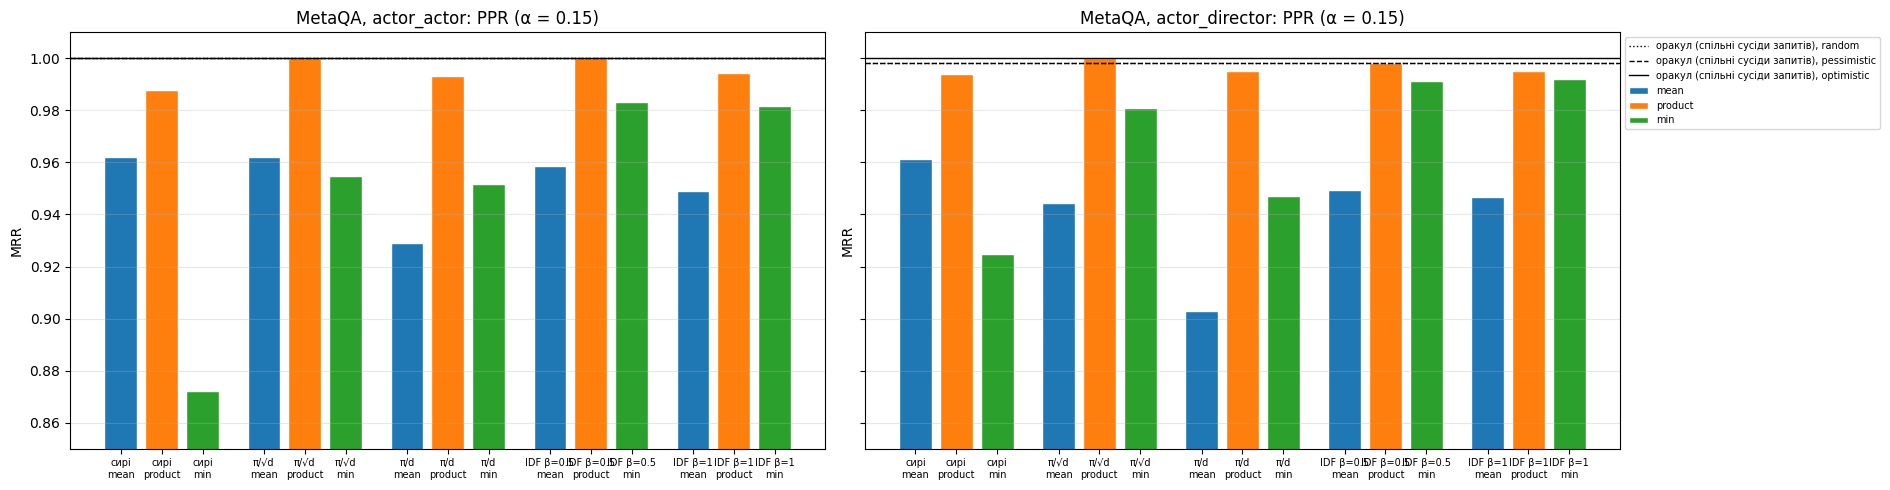

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(19, 5), sharey=True)
for ax, kind in zip(axs, ("actor_actor", "actor_director")):
    sub = mq_m[(mq_m["kind"] == kind) & (mq_m["метод"] == "PPR, α=0.15")]
    labels = []; x = 0
    for nlab in GRAPHS:
        for i, comb in enumerate(COMBS):
            v = sub[(sub["нормування"] == nlab) & (sub["поєднання"] == comb)]["MRR"].item()
            ax.bar(x, v, color=f"C{i}", edgecolor="white", label=comb if nlab == "сирі" else None)
            labels.append(f"{nlab}\n{comb}"); x += 1
        x += 0.5
    for t, ls in zip(TIES, (":", "--", "-")):
        v = mq_m[(mq_m["kind"] == kind) & (mq_m["метод"] == "спільні сусіди запитів (оракул)") & (mq_m["нічиї"] == t)]["MRR"].item()
        ax.axhline(v, color="k", ls=ls, lw=1, label=f"оракул (спільні сусіди запитів), {t}")
    ax.set_xticks([i + 0.5 * (i // 3) for i in range(15)]); ax.set_xticklabels(labels, fontsize=7)
    ax.set_title(f"MetaQA, {kind}: PPR (α = 0.15)"); ax.set_ylabel("MRR"); ax.grid(alpha=0.3, axis="y")
    ax.set_ylim(0.85, 1.01)
axs[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.savefig(FIG / "05_metaqa_pary.png", dpi=200); plt.show()

## Завдання 5.3. Зведення і рекомендований варіант

Зводимо всі комбінації «модель × нормування × поєднання», які є на обох наборах даних. IDF визначено лише для MetaQA, тож у зведення він не входить. Теплове ядро з t*(0.05) об'єднуємо в один рядок, хоча на двох графах t* різне (6.97 і 7.89).

Колонки:
- **синтетика:** середній MRR і **найгірший випадок** за конфігураціями (r, bridge_degree);
- **MetaQA:** MRR для обох типів пар.

Рекомендований варіант обираємо за найгіршим випадком на обох наборах даних, а не за середнім на одному.

In [14]:
key = lambda x: x.replace(f"t={T005_SYN:.2f}", "t*(0.05)").replace(f"t={T005_MQ}", "t*(0.05)")
sd = syn_m[syn_m["модель"] != "базовий"].copy(); sd["варіант"] = sd["метод"].map(key)
md_ = mq_m[mq_m["модель"] != "базовий"].copy(); md_["варіант"] = md_["метод"].map(key)
gk = ["варіант", "нормування", "поєднання"]
cell = sd.groupby(gk + ["r", "bridge_degree"])["MRR"].mean()
summary = pd.DataFrame({"синт_середнє": sd.groupby(gk)["MRR"].mean(), "синт_найгірший": cell.groupby(gk).min()})
summary["де_найгірший_(r,bd)"] = cell.groupby(gk).idxmin().map(lambda x: (x[3], x[4]))
summary = summary.join(md_.pivot_table(index=gk, columns="kind", values="MRR"), how="inner")
summary["MetaQA_найгірший"] = summary[["actor_actor", "actor_director"]].min(axis=1)
summary["найгірший_на_обох"] = summary[["синт_найгірший", "MetaQA_найгірший"]].min(axis=1)
summary = summary.sort_values("найгірший_на_обох", ascending=False)
summary.to_csv(RES / "05_zvedennya.csv")
pd.set_option("display.max_rows", 120)
display(summary)
REC = summary.index[0]
print(f"Рекомендований варіант (за найгіршим випадком на обох наборах): {REC}; "
      f"далі: {list(summary.index[1:3])}")
best_mean = summary["синт_середнє"].idxmax()
print(f"Для порівняння — найкращий за середнім на синтетиці: {best_mean}: "
      f"синтетика {summary.loc[best_mean, 'синт_середнє']:.3f}, MetaQA найгірший {summary.loc[best_mean, 'MetaQA_найгірший']:.3f}")

синт_середнє  синт_найгірший де_найгірший_(r,bd)  actor_actor  actor_director  MetaQA_найгірший  найгірший_на_обох
варіант                нормування поєднання                                                                                                                    
теплове ядро, t=1      π/√d       product           0.891           0.551              (1, 1)        1.000           1.000             1.000              0.551
теплове ядро, t=5.67   π/√d       product           0.868           0.515              (2, 1)        0.995           0.992             0.992              0.515
PPR, α=0.05            π/d        min               0.896           0.487              (1, 1)        0.937           0.937             0.937              0.487
PPR, α=0.15            π/d        min               0.855           0.464              (1, 1)        0.952           0.947             0.947              0.464
PPR, α=0.5             π/d        min               0.823           0.464              (1, 1)        0.998           0.997             0.997              0.464
теплове ядро, t=1      π/d        min               0.808           0.462              (1, 1)        0.998           0.998             0.998              0.462
PPR, α=0.05            π/√d       min               0.901           0.439              (1, 1)        0.929           0.955             0.929              0.439
теплове ядро, t*(0.05) π/√d       product           0.835           0.415              (3, 1)        0.969           0.977             0.969              0.415
                                  min               0.876           0.378              (1, 1)        0.900           0.905             0.900              0.378
теплове ядро, t=1      π/d        product           0.826           0.376              (2, 8)        1.000           1.000             1.000              0.376
PPR, α=0.15            π/√d       min               0.853           0.361              (1, 1)        0.955           0.981             0.955              0.361
теплове ядро, t=5.67   π/√d       min               0.855           0.357              (1, 1)        0.924           0.951             0.924              0.357
теплове ядро, t=1      π/√d       min               0.807           0.344              (1, 1)        1.000           1.000             1.000              0.344
PPR, α=0.5             π/√d       min               0.813           0.343              (1, 1)        0.998           1.000             0.998              0.343
теплове ядро, t=1      сирі       min               0.793           0.334              (1, 1)        0.967           0.982             0.967              0.334
PPR, α=0.5             сирі       min               0.798           0.333              (1, 1)        0.957           0.977             0.957              0.333
теплове ядро, t*(0.05) сирі       min               0.826           0.331              (1, 1)        0.749           0.791             0.749              0.331
PPR, α=0.15            сирі       min               0.824           0.331              (1, 1)        0.872           0.925             0.872              0.331
теплове ядро, t=5.67   сирі       min               0.814           0.331              (1, 1)        0.815           0.855             0.815              0.331
PPR, α=0.05            сирі       min               0.854           0.330              (1, 1)        0.771           0.811             0.771              0.330
PPR, α=0.5             π/√d       product           0.688           0.291              (3, 1)        1.000           1.000             1.000              0.291
PPR, α=0.15            π/√d       product           0.678           0.279              (3, 1)        1.000           1.000             1.000              0.279
теплове ядро, t=5.67   π/d        product           0.924           0.674              (1, 8)        0.267           0.263             0.263              0.263
                                  min        

Рекомендований варіант (за найгіршим випадком на обох наборах): ('теплове ядро, t=1', 'π/√d', 'product'); далі: [('теплове ядро, t=5.67', 'π/√d', 'product'), ('PPR, α=0.05', 'π/d', 'min')]
Для порівняння — найкращий за середнім на синтетиці: ('теплове ядро, t*(0.05)', 'π/d', 'product'): синтетика 0.945, MetaQA найгірший 0.240


### Фіксований варіант проти фіксованого базового методу

Рекомендований варіант порівнюємо з одним фіксованим базовим методом — сумою відстаней (найкоротший шлях, agg = mean) — з трьома межами розбиття нічиїх. Тут немає вибору найкращого з багатьох.

In [15]:
rec_sd = sd[(sd["варіант"] == REC[0]) & (sd["нормування"] == REC[1]) & (sd["поєднання"] == REC[2])]
fixed = rec_sd.groupby("r")["MRR"].mean().rename(f"{REC[0]}, {REC[1]}, {REC[2]}").to_frame()
bb = syn_m[syn_m["метод"] == "найкор. шлях, сума (agg=mean)"].groupby(["r", "нічиї"])["MRR"].mean().unstack()
fixed = fixed.join(bb.add_prefix("сума відстаней, "))
fixed.to_csv(RES / "05_rekomendovanyi_vs_bazovyi.csv")
display(fixed)
display(rec_sd.pivot_table(index="r", columns="bridge_degree", values="MRR"))

,"теплове ядро, t=1, π/√d, product","сума відстаней, optimistic","сума відстаней, pessimistic","сума відстаней, random"
r,,,,
1,0.770,1.000,0.509,0.696
2,0.900,0.996,0.226,0.586
3,0.931,0.983,0.118,0.471
4,0.961,0.939,0.057,0.321


bridge_degree,1,2,4,8
r,,,,
1,0.551,0.690,0.900,0.940
2,0.700,0.917,1.000,0.985
3,0.790,0.990,0.972,0.970
4,0.960,0.931,0.970,0.983


## Висновки

1. **Відповідь на питання ТЗ: мости найвище ранжує мультиплікативне поєднання, а адитивне їх майже не знаходить.**
   - Середній MRR правильного мосту для середнього (адитивного) поєднання становить 0.52–0.64 при r = 1 і падає до ≤ 0.08 при r = 2 та до 0.004–0.010 при r = 4: сума тягне вгору околи кожного запиту окремо.
   - Для далеких мостів найкращий мінімум з π/d: 0.871, 0.981 і 0.999 при r = 2, 3, 4. Найближчі (r = 1) краще знаходить добуток з π/d: 0.881.
   - Мости-дистрактори до третьої спільноти в топ-10 майже не потрапляють: їхня частка не перевищує 0.02.
2. **Степінь мосту і нормування.**
   - Добуток сирих оцінок підсилює хаби (~d_i²): MRR PPR зростає з 0.194 до 0.933, коли степінь мосту росте з 2 до 16.
   - Добуток з π/d (~d_i⁰) прибирає роль хаба «збирає масу», але лишає роль «розпорошує»: міст степеня 16 ділить свою масу на 16 сусідів, і MRR падає з 1.000 до 0.295 (PPR). У теплового ядра падіння менше: з 0.982 до 0.809.
   - π/√d (~d_i¹) — частковий компроміс. Для PPR-добутку він має найкращий найгірший випадок за степенем мосту (0.416 проти 0.295 у π/d і 0.194 у сирих оцінок). Для теплового ядра найгірший випадок кращий у π/d (0.809 проти 0.577).
   - Найстійкіше до степеня мосту поєднання — мінімум: 0.81–0.90 (π/d) і 0.73–0.97 (π/√d) для PPR.
3. **Немонотонність за r — наслідок того, як визначено r.** r — відстань до найближчого правильного мосту, тож при r = 1 лише в 34% пар обидва запити суміжні з одним і тим самим мостом. При r = 4 таких пар 97%. Для пар зі спільним мостом мінімум з π/d дає MRR = 1.000 при кожному r. Для пар без нього — 0.295 при r = 1, 0.804 при r = 2 і 0.985 при r = 3: кожен правильний міст тоді близький лише до одного запиту, і мінімум віддає перевагу «врівноваженим» вузлам посередині шляху. При r = 1 над правильним мостом стоять у середньому 0.4–1.7 вузла на найкоротшому шляху між запитами і 1.7–4.1 інших вузлів спільнот (медіанний степінь 6–7). Дистракторів і сусідів запитів серед них немає.
4. **Рекомендований варіант — теплове ядро з t = 1, π/√d і добутком.** Його обрано за найгіршим випадком на обох наборах даних: на синтетиці середнє 0.891 і найгірший випадок 0.551 (r = 1, міст степеня 2), на MetaQA 1.000 для обох типів пар. Близькі до нього теплове ядро з t = 5.67, π/√d і добутком (найгірший випадок 0.515) і PPR з α = 0.05, π/d і мінімумом (0.487). Найкращий за середнім на синтетиці варіант (теплове ядро, π/d, добуток: 0.945) на MetaQA дає лише 0.240. Отже, вибір за одним набором даних вводить в оману.
5. **Дифузія проти простого методу і MetaQA.**
   - **Синтетика, чесне порівняння:** рекомендований варіант проти суми відстаней (найкоротший шлях, agg = mean).

     | r | рекомендований | сума відстаней, random | різниця | optimistic (недосяжна) | pessimistic |
     |---|---|---|---|---|---|
     | 1 | 0.770 | 0.696 | +0.074 | 1.000 | 0.509 |
     | 2 | 0.900 | 0.586 | +0.314 | 0.996 | 0.226 |
     | 3 | 0.931 | 0.471 | +0.460 | 0.983 | 0.118 |
     | 4 | 0.961 | 0.321 | +0.640 | 0.939 | 0.057 |

     **Як читати межі нічиїх.** Оптимістична межа на практиці недосяжна: щоб поставити правильний міст першим серед вузлів з однаковою оцінкою, треба заздалегідь знати відповідь. Реалістичне порівняння — з випадковим розбиттям нічиїх. **За ним рекомендований варіант дифузії виграє при кожному r, і відрив зростає з відстанню до мосту: з 0.770 проти 0.696 при r = 1 до 0.961 проти 0.321 при r = 4.** Причина: сума відстаней однакова для правильного мосту і для всіх проміжних вузлів на найкоротших шляхах, і що далі міст, то більше таких нічиїх. Дифузія ці вузли розрізняє.

     **Додатково.** Оптимістичну межу дифузія перевищує лише при r = 4 (0.961 проти 0.939). При r = 1–3 ідеальне розбиття нічиїх дало б простому методу 0.983–1.000. Тобто майже вся перевага дифузії на чистому графі — у розрізненні вузлів, які простий метод вважає рівними. Таблиця «верхня межа дифузії», де для кожного r обрано найкращий з ~18 варіантів, дає 0.940–1.000 і цю перевагу завищує.
   - **MetaQA:** оракул «спільні сусіди запитів» (k-hop ∩, k = 1) має MRR 1.000 і 0.998. Рекомендований варіант і PPR (α = 0.15) з π/√d і добутком досягають 1.000 і не поступаються оракулу в жодній парі навіть за оптимістичного розбиття його нічиїх. Середнє поєднання слабше (0.90–0.96).
   - **Теплове ядро з π/d провалюється на MetaQA** (MRR 0.235–0.267) через перекорекцію з п. 3. Над правильним фільмом стоять 5–7 вузлів на пару, з них 84–90% мають степінь 1, а 68–96% є сусідами самого фільму. Їхня оцінка після ділення на d у 1.24–1.45 раза більша за оцінку фільму. У PPR з π/d таких вузлів лише 0.03–0.77 на пару.
   - Схожість Σ|N(v) ∩ N(q)| дає MRR 0.002, бо на дводольному графі вона рівна нулю для всіх вузлів на непарній відстані від запиту, а спільні фільми саме там (детальніше — у п. 6).